In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import joblib

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(r"..\data\AmesHousing.csv")

df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
print("Shape:", df.shape)

Shape: (2930, 82)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [6]:
df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [7]:
df.isnull().sum().sum()

np.int64(15749)

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64

In [9]:
print("Duplicate Rows:", df.duplicated().sum()) #no duplicates

Duplicate Rows: 0


In [10]:
#features not available, so instead fill with None, for categorical columns
none_cols = [
    'Pool QC','Misc Feature','Alley','Fence',
    'Fireplace Qu','Garage Type','Garage Finish',
    'Garage Qual','Garage Cond',
    'Bsmt Qual','Bsmt Cond','Bsmt Exposure',
    'BsmtFin Type 1','BsmtFin Type 2',
    'Mas Vnr Type'
]

for col in none_cols:
    if col in df.columns:
        df[col] = df[col].fillna("None")

In [11]:
#for numerical column
df["Garage Yr Blt"] = df["Garage Yr Blt"].fillna(0)
df["Mas Vnr Area"] = df["Mas Vnr Area"].fillna(0)

In [12]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [13]:
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [14]:
df.isnull().sum().sum()

np.int64(0)

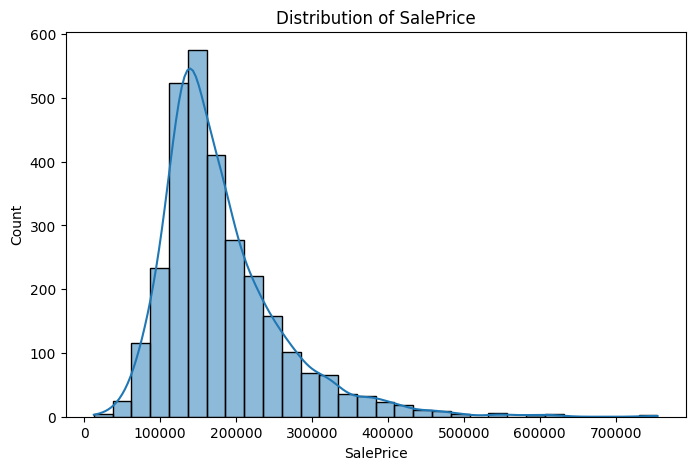

In [ ]:
#Univariet graph
plt.figure(figsize=(8,5))

sns.histplot(df["SalePrice"], bins=30, kde=True) #bins divide the SalePrice into 30 equal intervals
#kde adds the smooth density curve

plt.title("Distribution of SalePrice")

plt.show()

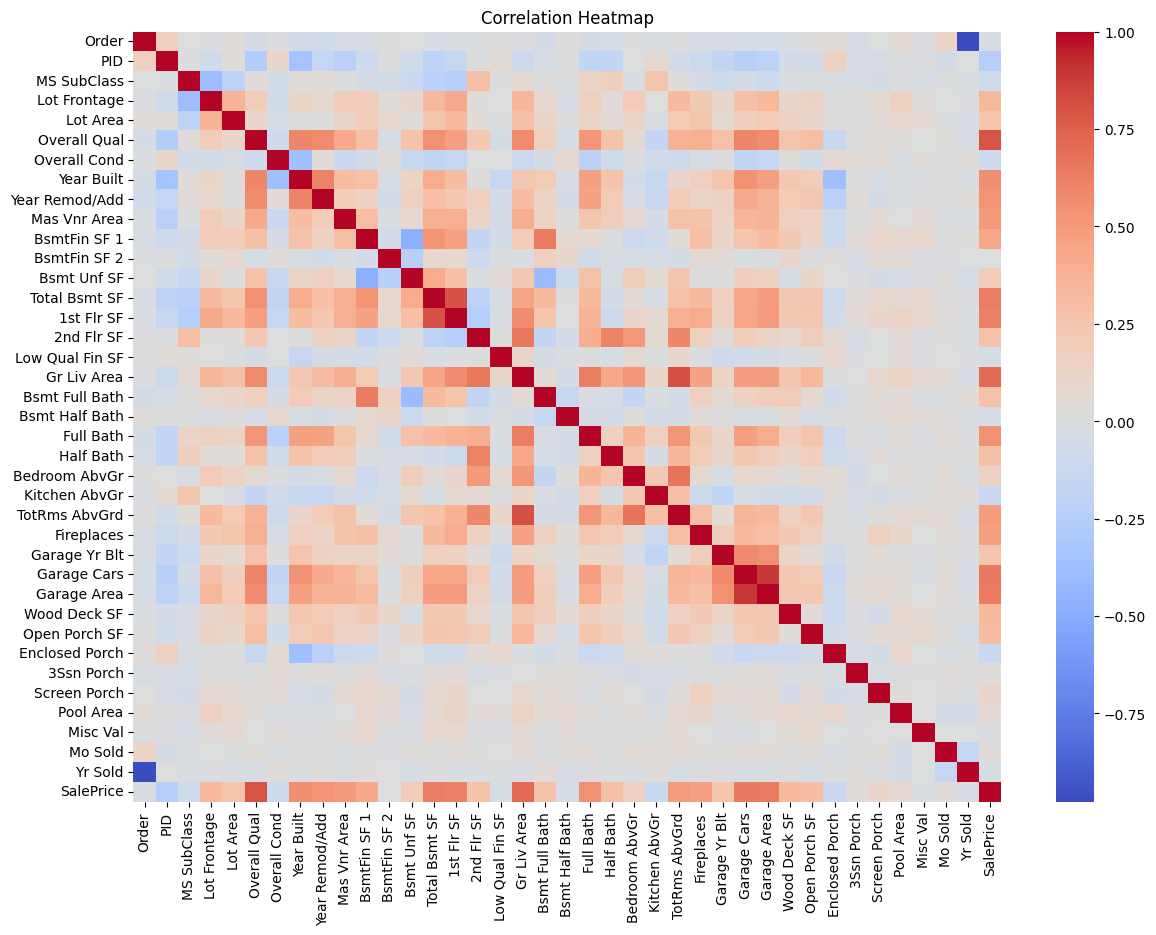

In [ ]:
#correlation heatmap for all numerical columns
#to know which features are related to house price
#for model training
plt.figure(figsize=(14,10))

corr = df.corr(numeric_only=True)
#ranges from -1 to +1
sns.heatmap(corr, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [17]:
corr = df.corr(numeric_only=True)

top_corr = corr["SalePrice"].sort_values(ascending=False)

print(top_corr.head(15))

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647812
Garage Area       0.640381
Total Bsmt SF     0.632164
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Mas Vnr Area      0.502196
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432862
Lot Frontage      0.340256
Name: SalePrice, dtype: float64


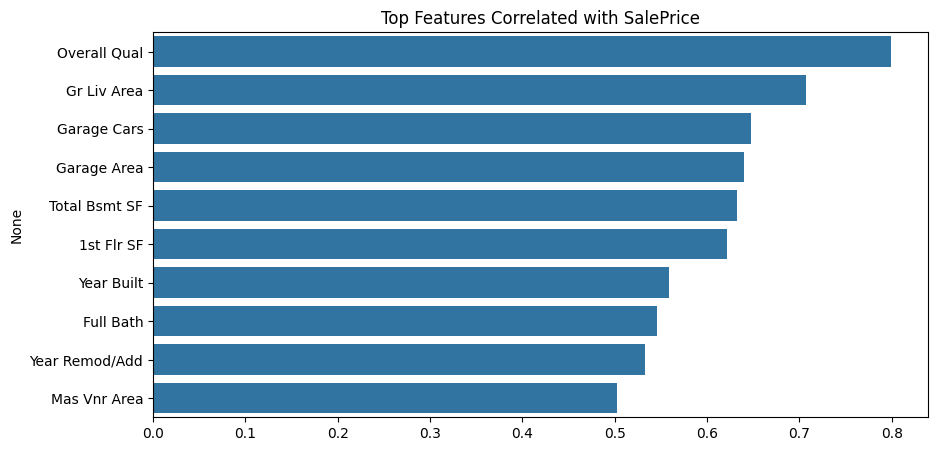

In [ ]:
#how strongly feature is correlated with SalePrice
top_features = top_corr[1:11]

plt.figure(figsize=(10,5))
sns.barplot(
    x=top_features.values,
    y=top_features.index
)
plt.title("Top Features Correlated with SalePrice")
plt.show()

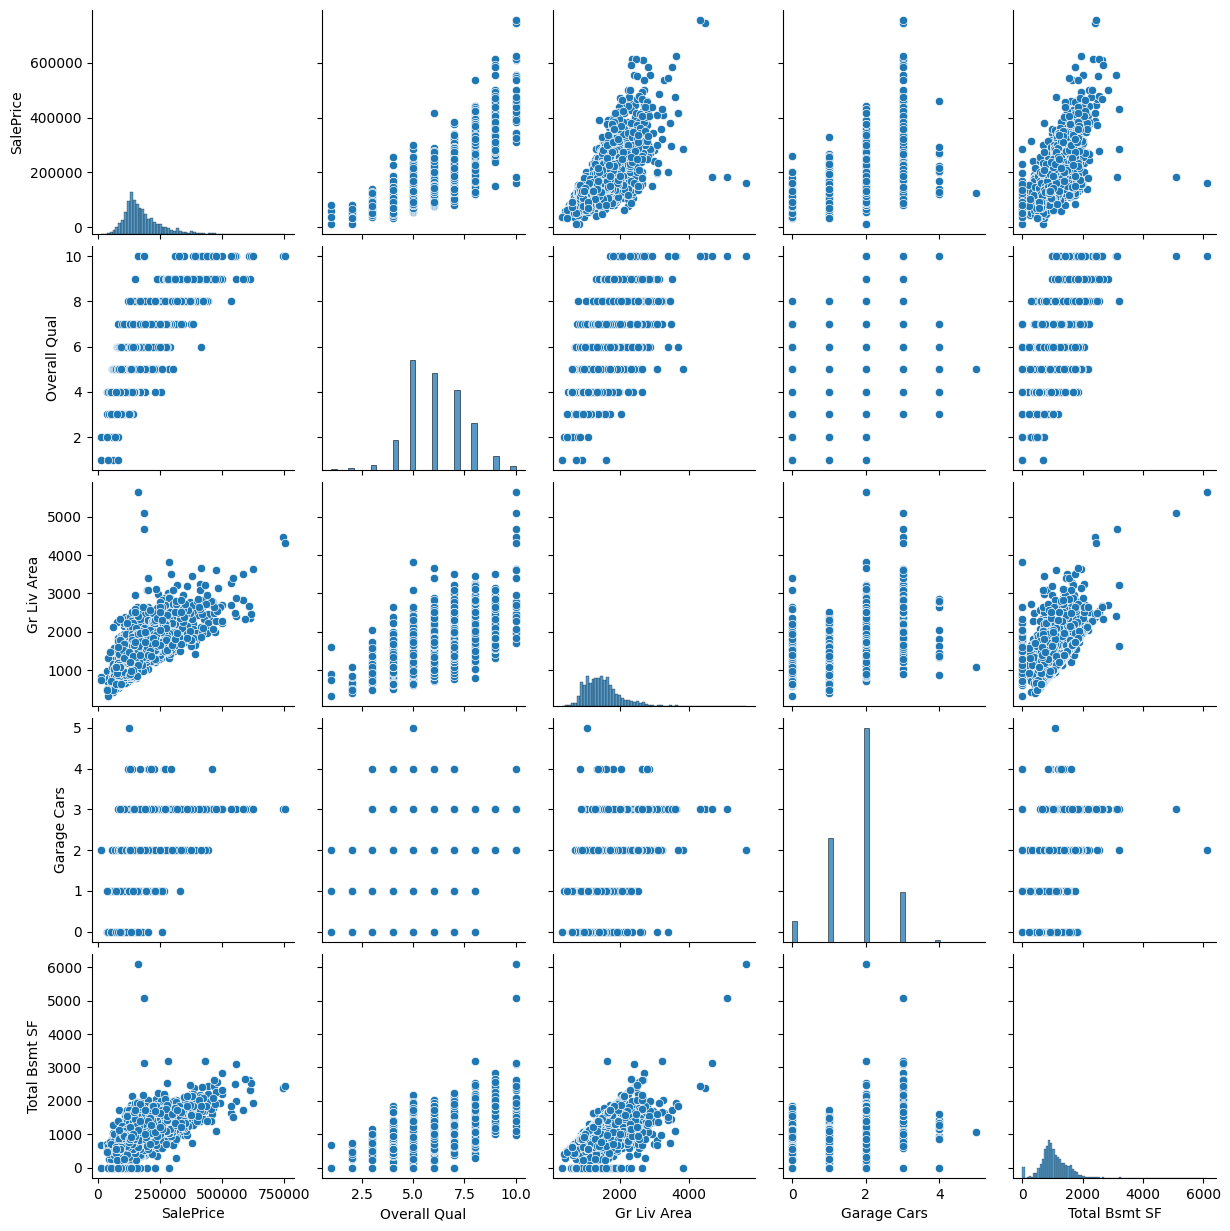

In [19]:
cols = [
    "SalePrice",
    "Overall Qual",
    "Gr Liv Area",
    "Garage Cars",
    "Total Bsmt SF"
]

sns.pairplot(df[cols])

plt.show()

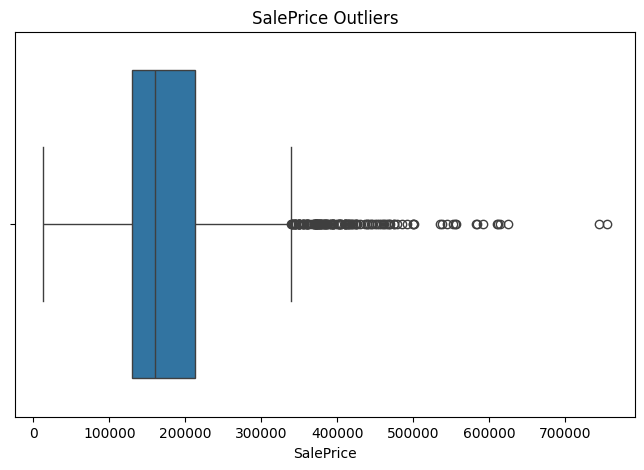

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["SalePrice"])

plt.title("SalePrice Outliers")

plt.show()

In [21]:
features = [
    "Overall Qual",
    "Gr Liv Area",
    "Garage Cars",
    "Garage Area",
    "Year Built",
    "Full Bath",
    "Lot Area",
    "Total Bsmt SF"
]

X = df[features]
y = df["SalePrice"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [24]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Linear Regression Performance")
print("-" * 35)
print(f"R² Score : {r2:.4f}")
print(f"MAE       : {mae:.2f}")
print(f"RMSE      : {rmse:.2f}")

Linear Regression Performance
-----------------------------------
R² Score : 0.8030
MAE       : 25029.96
RMSE      : 39743.09


In [25]:
results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

results.head(10)

,Actual Price,Predicted Price
1357,161000,189585.496746
2367,116000,128232.325102
2822,196500,217559.380272
2126,123600,94679.333427
1544,126000,116531.499598
2415,174190,188213.464392
2227,200000,203648.060952
410,148500,165251.977169
761,88750,60507.717804
436,409900,317628.460328


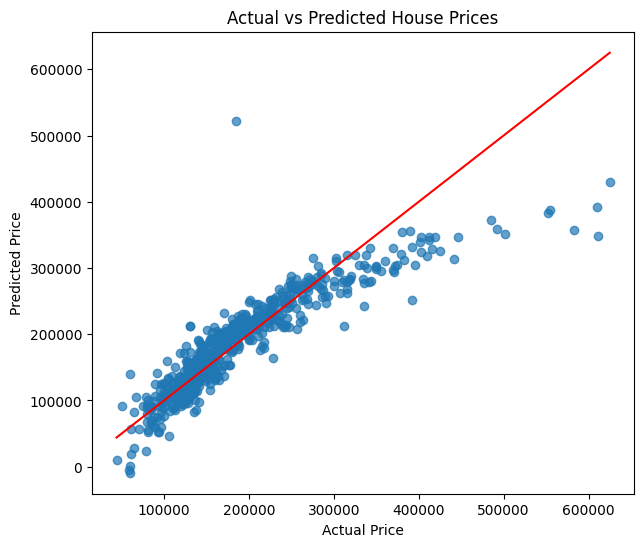

In [26]:
plt.figure(figsize=(7,6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [27]:
joblib.dump(
    lr,
    "../model/house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
